In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

In [29]:
data = pd.read_csv(r'..\data\nova_pay_combined.csv')

## Data Quality Assessment

In [46]:
round(data.isnull().mean()*100, 2)

transaction_id               0.00
customer_id                  0.00
timestamp                    0.25
home_country                 0.00
source_currency              0.00
dest_currency                0.00
channel                      0.00
amount_src                   0.00
amount_usd                   2.68
fee                          2.59
exchange_rate_src_to_dest    0.00
device_id                    0.00
new_device                   0.00
ip_address                   2.68
ip_country                   2.64
location_mismatch            0.00
ip_risk_score                0.00
kyc_tier                     2.63
account_age_days             0.00
device_trust_score           2.59
chargeback_history_count     0.00
risk_score_internal          0.00
txn_velocity_1h              0.00
txn_velocity_24h             0.00
corridor_risk                0.00
is_fraud                     0.00
dtype: float64

Several columns have missing values: `timestamp`, `amount_usd`, `fee`, `ip_address`, `ip_country`, `kyc_tier`, and `device_trust_score`. Before imputing anything, check whether categorical columns also hide inconsistent formatting (casing, whitespace, placeholder strings) that would otherwise masquerade as legitimate categories.

## Do a full categorical audit

In [4]:
for col in data.select_dtypes(include=['str']).columns.tolist():
    print(data[col].value_counts())
    print('-----------------------------------')

transaction_id
4662cb2d-21b2-4390-ba38-5a1eddebdc7c    2
e69d481f-2ee3-4621-a58a-73fec8c63eca    2
8537371a-7eae-4108-89c9-5660e5025a88    2
2e553c23-063e-4b5e-aa2e-8a41d6aa61ca    2
a9198fb0-d831-48df-b434-c30a39078aa3    2
                                       ..
b5ef3323-46d2-4f6c-9c19-43df4e55df48    1
54f00f78-94aa-4a08-bf6b-12877aa47186    1
6a51f0e8-f5d1-4fe6-91a0-655fccd79fa5    1
4aad7389-2b62-4885-a23e-aa3ecd5cfaf9    1
fdffeb16-192a-4483-9b1e-9928e23269c2    1
Name: count, Length: 11200, dtype: int64
-----------------------------------
customer_id
402cccc9-28de-45b3-9af7-cc5302aa1f93    1510
d71c91b4-fee8-4104-9856-a5c6109a62e3    1355
7041b9c1-3719-4ca8-9a6b-811b47cea6c0    1345
6d0d9b27-fa26-45f8-93b1-2df29d182d9c    1066
af8ca4c4-8703-4c55-b66c-2b76cd70040d     915
                                        ... 
8734e6a7-f34e-49f2-b559-1d62a756664c       1
c18070a6-bdb9-4df3-9df7-5d92c0bff424       1
2003e2a1-f3b1-4e2e-8d0e-488cfacf68ca       1
8b1cf558-4ed7-48ee-b330-75db6

**Issues found:**
- `channel`: `mobille`/`weeb` typos, inconsistent casing (`MOBILE`, `WEB`, `ATm`), leading whitespace, and an `unknown` placeholder.
- `kyc_tier`: typos (`standrd`, `enhancd`), inconsistent casing, whitespace, and `nan`/`NAN` placeholders.
- `home_country` / `ip_country`: leading/trailing whitespace and an `unknown` placeholder.

These are standardized in the next section.

## Check for Duplicates

In [5]:
data.duplicated().sum()

np.int64(200)

## Check for Datatypes

In [6]:
data.dtypes

transaction_id                   str
customer_id                      str
timestamp                        str
home_country                     str
source_currency                  str
dest_currency                    str
channel                          str
amount_src                       str
amount_usd                   float64
fee                          float64
exchange_rate_src_to_dest    float64
device_id                        str
new_device                      bool
ip_address                       str
ip_country                       str
location_mismatch               bool
ip_risk_score                float64
kyc_tier                         str
account_age_days               int64
device_trust_score           float64
chargeback_history_count       int64
risk_score_internal          float64
txn_velocity_1h                int64
txn_velocity_24h               int64
corridor_risk                float64
is_fraud                       int64
dtype: object

`timestamp`, `amt_src`, have inconsistent datatypes

## Check for Outliers

In [33]:
data[data['fee'] == 1]['fee']

29      1.0
3305    1.0
4539    1.0
5084    1.0
6011    1.0
6761    1.0
7074    1.0
7296    1.0
8345    1.0
9545    1.0
Name: fee, dtype: float64

In [45]:
data['fee'].sample(20)

10822     1.91
2892      1.38
3489      4.08
2658     11.12
3929      4.75
3926      4.74
4028      5.32
11124     9.01
1180      8.05
1992      7.19
4725      9.48
1894      3.58
7792      2.70
3525      4.15
2615      1.77
10593     3.65
8784      3.27
8625      2.95
4545      2.39
3765      3.03
Name: fee, dtype: float64

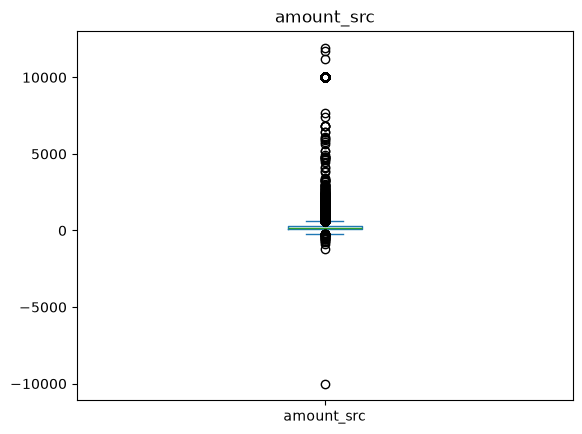

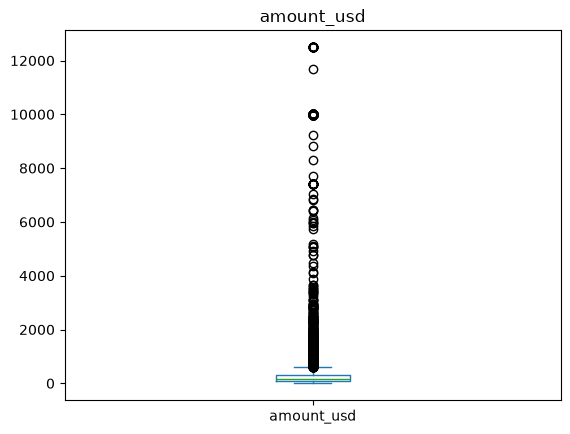

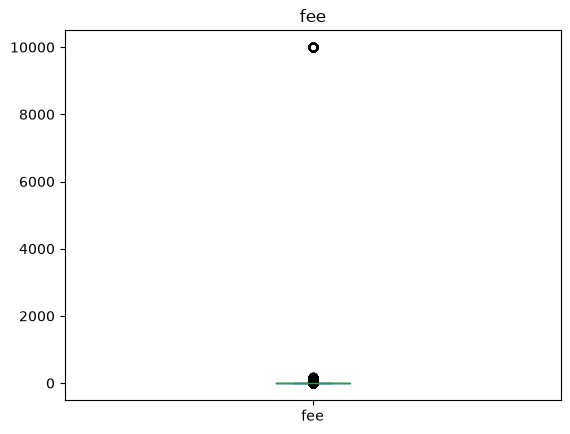

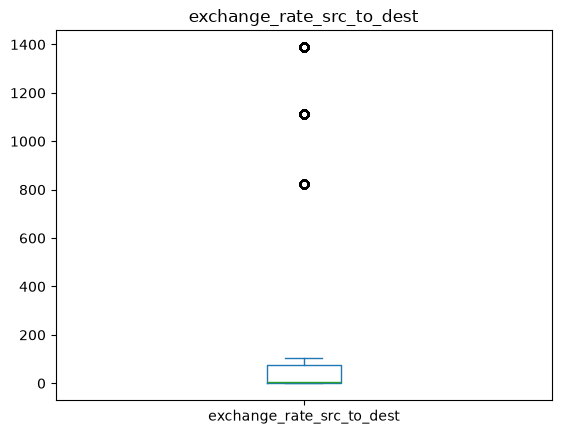

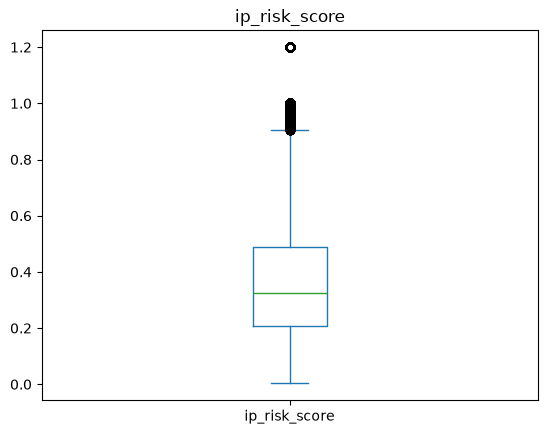

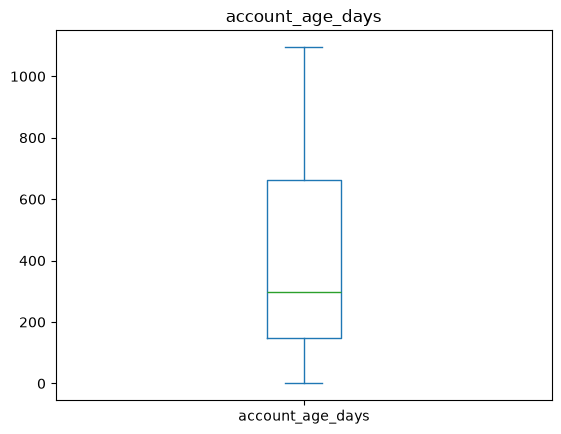

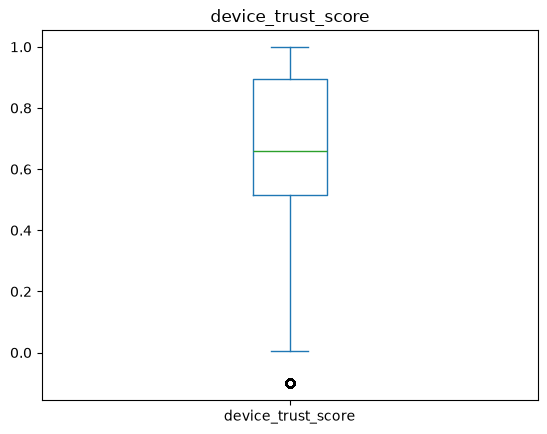

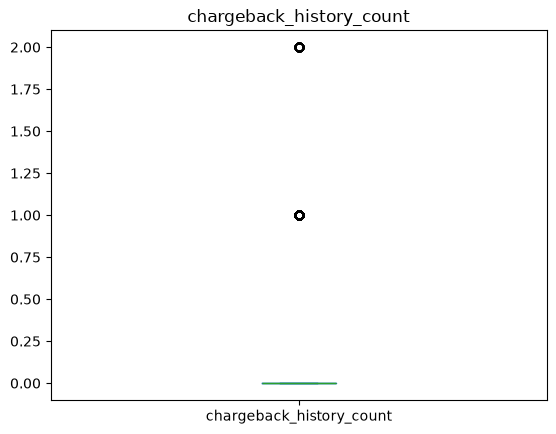

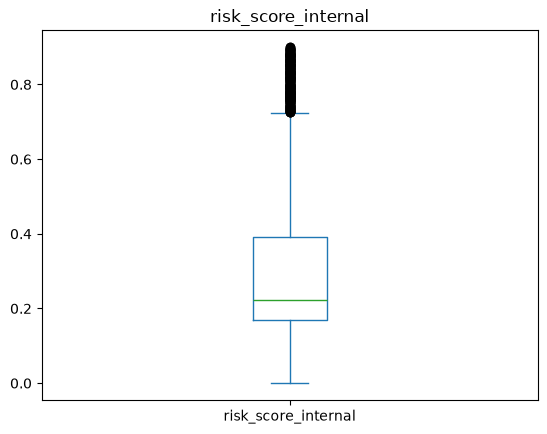

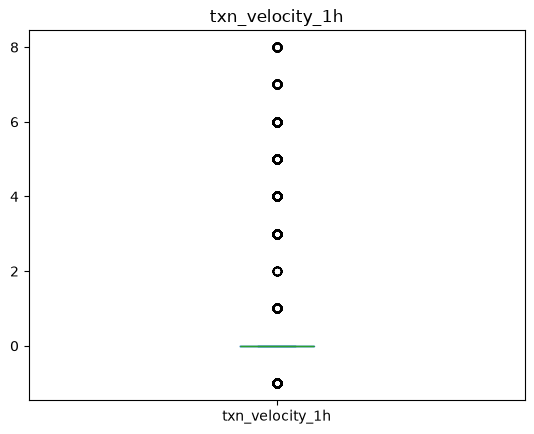

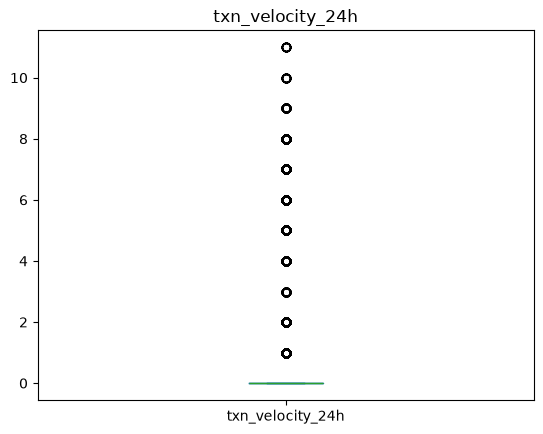

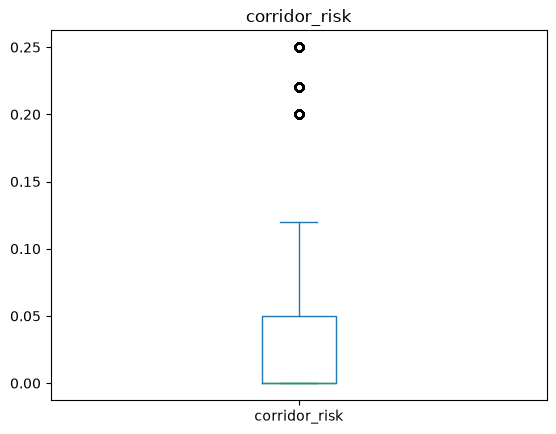

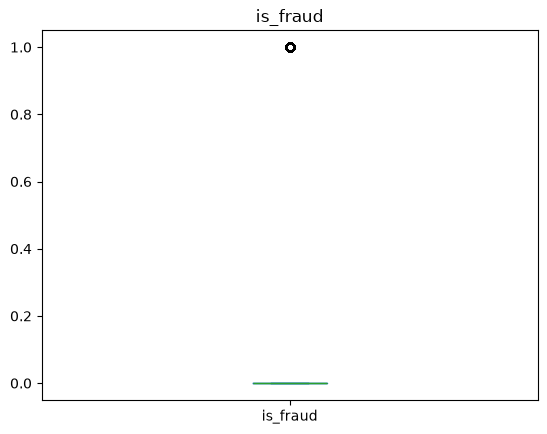

In [57]:
import numpy as np

for col in data.select_dtypes(include=np.number).columns.tolist():
    data[col].plot(kind='box')
    plt.title(col)
    plt.show()

## Data Cleaning & Standardization

In [54]:
data['txn_velocity_1h']

0        0
1        0
2        0
3        0
4        0
        ..
11395    1
11396    3
11397    3
11398    0
11399    4
Name: txn_velocity_1h, Length: 11400, dtype: int64

In [60]:
data[data['txn_velocity_1h'] < 0][['txn_velocity_1h', 'fee', 'is_fraud', 'amount_src', 'amount_usd']].sample(40)

,txn_velocity_1h,fee,is_fraud,amount_src,amount_usd
4826,-1,9999.99,0,-502.27,502.27
6056,-1,-1.00,0,231.53,231.53
7611,-1,-1.00,0,77.37,96.72
4648,-1,-1.00,0,172.71,127.81
8442,-1,-1.00,0,62.44,78.05
7916,-1,9999.99,0,-252.90,187.14
6369,-1,-1.00,0,164.69,205.86
3630,-1,9999.99,0,-58.23,58.23
10198,-1,9999.99,0,-168.96,211.20
8680,-1,-1.00,0,117.14,146.42


Dealing with Datatypes: reparse timestamp and amount_src

In [56]:
data['timestamp'] = pd.to_datetime(data['timestamp'], errors='coerce', dayfirst=True)
data['amount_src'] = pd.to_numeric(data['amount_src'], errors='coerce')

Drop duplicates using the id colummns as the subsets

In [61]:
data.drop_duplicates(subset=['transaction_id', 'customer_id', 'device_id', 'ip_address'], inplace=True)

Dealing with categorical issues

In [10]:
cat_cols = data.select_dtypes(include=['object']).drop(columns=['transaction_id', 'customer_id', 'device_id', 'ip_address']).columns.tolist()

for col in cat_cols:
    data[col] = data[col].str.strip().str.lower()


typo_correction = {
    'ip_country': {'nan': 'unknown'},
    'kyc_tier': {'nan': 'unknown', 'standrd': 'standard', 'enhancd': 'enhanced'},
    'channel': {'weeb': 'web', 'mobille': 'mobile'}
}

for col, corrections in typo_correction.items():
    data[col] = data[col].replace(corrections)

C:\Users\HomePC\AppData\Local\Temp\ipykernel_10020\320712395.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = data.select_dtypes(include=['object']).drop(columns=['transaction_id', 'customer_id', 'device_id', 'ip_address']).columns.tolist()


Dealing with missing values

In [11]:
data['amount_src']  = data['amount_src'].abs()

In [12]:
# fill amount src with median
data['amount_src'] = data['amount_src'].fillna(data['amount_src'].median())

# calculate rates conversion based on the data and return the values
rates = round((data['amount_usd']/data['amount_src']).groupby(data['source_currency']).mean(), 1)
print(rates.values)

# fill amount_usd with the multiple of amount_src and rates values
data['amount_usd'] = data['amount_usd'].fillna(data['amount_src'] * data['source_currency'].map(rates))

[0.7 1.3 1. ]


In [13]:
# fill fee null values using group-based imputation
data['fee'] = data.groupby('channel')['fee'].transform(lambda x: x.fillna(x.median()))
data['fee']

0         4.25
1         4.24
2         2.70
3         2.22
4         3.61
         ...  
11395     5.24
11396     8.86
11397     4.00
11398     1.96
11399    19.34
Name: fee, Length: 11200, dtype: float64

In [14]:
# ip_country: fallback to home_country
data['ip_country'] = data['ip_country'].fillna(data['home_country'])

In [15]:
data['device_trust_score'] = data['device_trust_score'].fillna(data['device_trust_score'].median())

In [16]:
data = data.dropna(subset=['timestamp'])

In [17]:
Q1 = data['fee'].quantile(0.25)
Q3 = data['fee'].quantile(0.75)

IQR = Q3 - Q1
lower_bound = Q1 - (100 * IQR)
upper_bound = Q3 + (100 * IQR)

print(lower_bound)
print(upper_bound)

data[(data['fee'] < lower_bound) | (data['fee'] > upper_bound)]

-307.56
315.54


,transaction_id,customer_id,timestamp,home_country,source_currency,dest_currency,channel,amount_src,amount_usd,fee,...,ip_risk_score,kyc_tier,account_age_days,device_trust_score,chargeback_history_count,risk_score_internal,txn_velocity_1h,txn_velocity_24h,corridor_risk,is_fraud
328,3bcab4c7-dc2e-416c-b57e-266aafe46a47,d71c91b4-fee8-4104-9856-a5c6109a62e3,2022-10-11 03:14:05.468549+00:00,us,usd,ngn,mobile,37.08,37.08,9999.99,...,1.2,standard,298,-0.1,0,0.166,-1,0,0.25,0
564,8e0f5d06-a518-4b0c-ab83-5208837bc5be,af8ca4c4-8703-4c55-b66c-2b76cd70040d,2022-07-12 17:24:01.468549+00:00,us,usd,usd,web,176.92,176.92,9999.99,...,1.2,standard,1018,-0.1,0,0.087,-1,0,0.00,0
576,064c0207-1b3c-4328-b0b9-7ea68a70ee1f,6d0d9b27-fa26-45f8-93b1-2df29d182d9c,2022-08-12 16:48:52.468549+00:00,us,usd,cad,mobile,702.71,702.71,9999.99,...,1.2,enhanced,367,-0.1,0,0.176,-1,0,0.00,0
602,1d2465a1-14b6-48d9-a74d-76a2dddf5e65,67c2c6b3-ef0a-4777-a3f1-c84a851bb6ad,2022-11-12 19:23:29.468549+00:00,ca,cad,cad,web,203.83,150.83,9999.99,...,1.2,standard,947,-0.1,0,0.268,-1,0,0.00,0
798,883403f5-fd2f-4b39-824e-9710485a983e,7041b9c1-3719-4ca8-9a6b-811b47cea6c0,2023-01-01 02:40:14.468549+00:00,uk,gbp,php,mobile,168.96,211.20,9999.99,...,1.2,standard,4,-0.1,0,0.407,-1,0,0.00,0
1418,ae0c1cd8-7f7e-4424-938f-7f7242ff197f,402cccc9-28de-45b3-9af7-cc5302aa1f93,2023-11-03 14:21:45.468549+00:00,us,usd,gbp,web,504.71,504.71,9999.99,...,1.2,standard,263,-0.1,0,0.223,-1,0,0.00,0
1429,873a17a6-91b1-434c-9908-2bf57fefa746,402cccc9-28de-45b3-9af7-cc5302aa1f93,2023-12-03 19:53:56.468549+00:00,us,usd,ngn,web,144.10,144.10,9999.99,...,1.2,standard,263,-0.1,0,0.223,-1,0,0.25,0
1664,00ceaf20-a2a2-4cf9-9f02-15445a15e48c,d71c91b4-fee8-4104-9856-a5c6109a62e3,2023-05-04 21:17:25.468549+00:00,us,usd,php,atm,59.01,59.01,9999.99,...,1.2,standard,298,-0.1,0,0.166,-1,0,0.10,0
1943,6e8ae26b-ef8b-4663-b806-ccd782e0b8bc,f7531a78-8bbe-4a85-b1e8-a0650edddc72,2023-06-05 15:57:39.468549+00:00,us,usd,php,mobile,251.88,251.88,9999.99,...,1.2,standard,1016,-0.1,0,0.247,-1,3,0.10,0
2484,55d4247c-7403-4b36-9d27-a092f6880652,d71c91b4-fee8-4104-9856-a5c6109a62e3,2023-04-07 23:20:43.468549+00:00,us,usd,php,web,153.12,153.12,9999.99,...,1.2,standard,298,-0.1,0,0.166,-1,0,0.10,0


In [18]:
# taking absolute value for the amount_src
print((data['amount_src'] < 0).sum())
data['amount_src'] = data['amount_src'].abs()

0


In [19]:
# replacing the outliers with trimmed mean
outlier = (data['fee'] < lower_bound) | (data['fee'] > upper_bound)
trimmed_mean = data.loc[~outlier, 'fee'].mean()

print(round(trimmed_mean, 2))

data.loc[outlier, 'fee'] = round(trimmed_mean, 2)

7.91


In [20]:
# drop irrelevant columns
data.drop(columns=['transaction_id', 'customer_id', 'device_id', 'ip_address'], inplace=True)

In [21]:
data.isnull().sum()

timestamp                      0
home_country                   0
source_currency                0
dest_currency                  0
channel                        0
amount_src                     0
amount_usd                     0
fee                            0
exchange_rate_src_to_dest      0
new_device                     0
ip_country                     0
location_mismatch              0
ip_risk_score                  0
kyc_tier                     118
account_age_days               0
device_trust_score             0
chargeback_history_count       0
risk_score_internal            0
txn_velocity_1h                0
txn_velocity_24h               0
corridor_risk                  0
is_fraud                       0
dtype: int64

## Train Base Model

1: Splitting data into train and test

2: Standardization and Encoding

3: Train our Base Model
- Instantiate the model
- fit the model
- run our prediction
- evaluate against test set

In [22]:
from sklearn.linear_model import LogisticRegression
from sklearn.compose import ColumnTransformer
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler

In [23]:
model_data = data.copy()

In [24]:
model_data = model_data.sort_values('timestamp').reset_index(drop=True)

X = model_data.drop(columns = ['is_fraud', 'timestamp'])
y = model_data['is_fraud']

X_train, X_test, y_train, y_test  = train_test_split(X, y, test_size=0.2, shuffle=False)

In [25]:
categorical_cols = X_train.select_dtypes(include=['object']).columns.tolist()
numerical_cols = X_train.select_dtypes(include=['number', 'bool']).columns.tolist()

preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(drop='first', handle_unknown='ignore'), categorical_cols),
        ('num', StandardScaler(), numerical_cols)
    ]
)

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

C:\Users\HomePC\AppData\Local\Temp\ipykernel_10020\2574487997.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = X_train.select_dtypes(include=['object']).columns.tolist()


In [26]:
model = LogisticRegression(random_state=42, class_weight='balanced')
model.fit(X_train_processed, y_train)

,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the follo

In [27]:
y_pred = model.predict(X_test_processed) # Inference

              precision    recall  f1-score   support

       Legit       0.99      0.94      0.96       744
       Fraud       0.68      0.90      0.77       101

    accuracy                           0.94       845
   macro avg       0.83      0.92      0.87       845
weighted avg       0.95      0.94      0.94       845



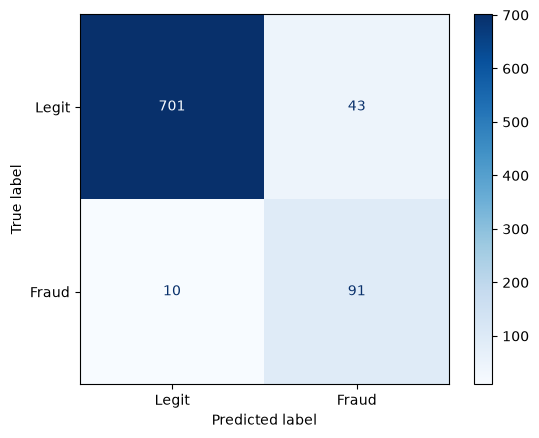

In [28]:
print(classification_report(y_test, y_pred, target_names=['Legit', 'Fraud']))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=['Legit', 'Fraud'], cmap="Blues")